# CIFAR-10 — CNN theo kiến trúc notebook mẫu

Đọc CIFAR-10 từ máy và huấn luyện CNN từ đầu, không dùng pretrained weights.

- 45.000 ảnh train, 5.000 validation, 10.000 test; ảnh RGB 32 × 32.
- Mean/std riêng từng kênh được tính trên train; validation/test dùng cùng thống kê.
- Train augment: flip, crop, xoay, dịch chuyển, zoom và color jitter nhẹ.
- Tám Conv2D thường theo bốn block 32–64–128–256, kèm BatchNorm, MaxPooling, Dropout và L2 như notebook mẫu.
- Giảm learning rate và EarlyStopping dựa trên val_loss; checkpoint lưu theo val_loss thấp nhất.
- Chạy lại notebook từ đầu sau khi thay đổi tiền xử lý/model; cần đo accuracy sau huấn luyện.


In [1]:
import tensorflow as tf

print(f"TensorFlow: {tf.__version__}")

TensorFlow: 2.21.0


Thư mục `cifar-10-batches-py` đã giải nén được đọc trực tiếp từ máy. Các batch pickle được giải mã bằng thư viện chuẩn Python, sau đó chuyển thành tensor TensorFlow; không tải lại dữ liệu.


In [2]:
from pathlib import Path
import pickle

# Tìm thư mục đã giải nén, dù notebook được chạy từ project root hay thư mục dataset/.
data_dir_candidates = [
    Path.cwd() / "cifar-10-batches-py",
    Path.cwd().parent / "cifar-10-batches-py",
]
DATA_DIR = next(
    (path.resolve() for path in data_dir_candidates if (path / "data_batch_1").is_file()),
    None,
)
if DATA_DIR is None:
    raise FileNotFoundError(
        "Không tìm thấy cifar-10-batches-py. Hãy đặt thư mục đã giải nén cạnh notebook."
    )


def load_cifar_batch(filename):
    # CIFAR-10 lưu ảnh dạng pickle: 3072 giá trị pixel theo thứ tự RGB.
    with (DATA_DIR / filename).open("rb") as file:
        batch = pickle.load(file, encoding="bytes")

    images = tf.convert_to_tensor(batch[b"data"], dtype=tf.uint8)
    images = tf.reshape(images, [-1, 3, 32, 32])
    images = tf.transpose(images, [0, 2, 3, 1])  # NCHW -> NHWC
    labels = tf.convert_to_tensor(batch[b"labels"], dtype=tf.int32)
    return images, labels


train_batches = [load_cifar_batch(f"data_batch_{i}") for i in range(1, 6)]
x_train = tf.concat([images for images, _ in train_batches], axis=0)
y_train = tf.concat([labels for _, labels in train_batches], axis=0)
x_test, y_test = load_cifar_batch("test_batch")

with (DATA_DIR / "batches.meta").open("rb") as file:
    metadata = pickle.load(file, encoding="bytes")
class_names = [name.decode("utf-8") for name in metadata[b"label_names"]]

print(f"Đã đọc dữ liệu từ: {DATA_DIR}")
print(f"Train images: {x_train.shape}, dtype={x_train.dtype}")
print(f"Train labels: {y_train.shape}, dtype={y_train.dtype}")
print(f"Test images : {x_test.shape}, dtype={x_test.dtype}")
print(f"Test labels : {y_test.shape}, dtype={y_test.dtype}")
print(f"Pixel range : {int(tf.reduce_min(x_train))} to {int(tf.reduce_max(x_train))}")
print(f"Classes ({len(class_names)}): {class_names}")

Đã đọc dữ liệu từ: /Users/bach/Downloads/AI Projects/fruit-detection/cifar-10-batches-py
Train images: (50000, 32, 32, 3), dtype=<dtype: 'uint8'>
Train labels: (50000,), dtype=<dtype: 'int32'>
Test images : (10000, 32, 32, 3), dtype=<dtype: 'uint8'>
Test labels : (10000,), dtype=<dtype: 'int32'>
Pixel range : 0 to 255
Classes (10): ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


## Preview ảnh gốc trước augmentation

Hiển thị một ảnh CIFAR-10 gốc cho mỗi class, lấy trực tiếp từ `x_train` và `y_train`. Cell này chạy trước khi tạo pipeline augmentation.

In [ ]:
import matplotlib.pyplot as plt

raw_labels = tf.reshape(y_train, [-1])
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for class_id, axis in enumerate(axes.flat):
    matching_indices = tf.where(raw_labels == class_id)[:, 0]
    sample_index = int(matching_indices[0])
    axis.imshow(x_train[sample_index].numpy())
    axis.set_title(class_names[class_id])
    axis.axis("off")

fig.suptitle("CIFAR-10 raw training images — before augmentation")
fig.tight_layout()
plt.show()

## Kiểm tra số lượng ảnh theo lớp

Mỗi nhãn là số từ 0 đến 9. Bảng dưới đây đếm số mẫu train và test cho từng lớp.

In [3]:
train_labels = tf.reshape(tf.convert_to_tensor(y_train), [-1])
test_labels = tf.reshape(tf.convert_to_tensor(y_test), [-1])

train_counts = tf.math.bincount(train_labels, minlength=10, maxlength=10)
test_counts = tf.math.bincount(test_labels, minlength=10, maxlength=10)

for index, name in enumerate(class_names):
    print(
        f"{index}: {name:>10} | "
        f"train={int(train_counts[index]) :>5} | "
        f"test={int(test_counts[index]) :>5}"
    )

0:   airplane | train= 5000 | test= 1000
1: automobile | train= 5000 | test= 1000
2:       bird | train= 5000 | test= 1000
3:        cat | train= 5000 | test= 1000
4:       deer | train= 5000 | test= 1000
5:        dog | train= 5000 | test= 1000
6:       frog | train= 5000 | test= 1000
7:      horse | train= 5000 | test= 1000
8:       ship | train= 5000 | test= 1000
9:      truck | train= 5000 | test= 1000


## Pipeline train/validation/test

Tách 5.000 ảnh validation trước, rồi tính mean/std riêng cho từng kênh RGB
chỉ trên 45.000 ảnh train. Augmentation chạy trên pixel [0, 1] trước khi
chuẩn hóa: flip ngang, random crop, xoay ±5°, dịch chuyển ±5%, zoom ±10%,
và color jitter nhẹ. Validation/test không augment và dùng cùng thống kê train.

In [4]:
BATCH_SIZE = 64
AUTOTUNE = tf.data.AUTOTUNE
VALIDATION_SIZE = 5_000

# Seed cố định để take/skip luôn tạo cùng phép chia train/validation.
shuffled_train = tf.data.Dataset.from_tensor_slices((x_train, y_train)).shuffle(
    buffer_size=len(x_train), seed=42, reshuffle_each_iteration=False
)
val_raw_ds = shuffled_train.take(VALIDATION_SIZE)
train_raw_ds = shuffled_train.skip(VALIDATION_SIZE)

# Tính mean/std theo từng kênh trên train gốc, không dùng validation hay test.
channel_sum = tf.zeros([3], dtype=tf.float64)
channel_square_sum = tf.zeros([3], dtype=tf.float64)
pixel_count = tf.constant(0.0, dtype=tf.float64)
for images, _ in train_raw_ds.batch(256):
    images = tf.cast(images, tf.float64) / 255.0
    channel_sum += tf.reduce_sum(images, axis=[0, 1, 2])
    channel_square_sum += tf.reduce_sum(tf.square(images), axis=[0, 1, 2])
    pixel_count += tf.cast(tf.shape(images)[0] * 32 * 32, tf.float64)

channel_mean = channel_sum / pixel_count
channel_variance = channel_square_sum / pixel_count - tf.square(channel_mean)
PIXEL_MEAN = tf.cast(channel_mean, tf.float32)
PIXEL_STD = tf.cast(tf.sqrt(tf.maximum(channel_variance, 1e-12)), tf.float32)
print("Train RGB mean:", PIXEL_MEAN.numpy())
print("Train RGB std :", PIXEL_STD.numpy())

random_rotation = tf.keras.layers.RandomRotation(
    factor=5.0 / 360.0,
    fill_mode="reflect",
    interpolation="bilinear",
    seed=44,
)
random_translation = tf.keras.layers.RandomTranslation(
    height_factor=0.05,
    width_factor=0.05,
    fill_mode="reflect",
    interpolation="bilinear",
    seed=45,
)
random_zoom = tf.keras.layers.RandomZoom(
    height_factor=(-0.1, 0.1),
    width_factor=(-0.1, 0.1),
    fill_mode="reflect",
    interpolation="bilinear",
    seed=46,
)


def normalize_example(image, label):
    image = tf.cast(image, tf.float32) / 255.0
    image = (image - PIXEL_MEAN) / PIXEL_STD
    return image, tf.cast(label, tf.int32)


def augment_example(image, label):
    # Augment từng ảnh trong miền pixel [0, 1], trước mean/std.
    image = tf.cast(image, tf.float32) / 255.0
    image = tf.image.random_flip_left_right(image)
    image = tf.pad(image, [[4, 4], [4, 4], [0, 0]], mode="REFLECT")
    image = tf.image.random_crop(image, size=[32, 32, 3])
    image = random_rotation(image, training=True)
    image = random_translation(image, training=True)
    image = random_zoom(image, training=True)
    image = tf.image.random_saturation(image, lower=0.9, upper=1.1)
    image = tf.image.random_hue(image, max_delta=0.02)
    image = tf.image.random_brightness(image, max_delta=0.05)
    image = tf.image.random_contrast(image, lower=0.9, upper=1.1)
    image = tf.clip_by_value(image, 0.0, 1.0)
    image = (image - PIXEL_MEAN) / PIXEL_STD
    return image, tf.cast(label, tf.int32)


train_ds = (
    train_raw_ds
    .shuffle(buffer_size=len(x_train) - VALIDATION_SIZE, seed=43,
             reshuffle_each_iteration=True)
    .map(augment_example, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

# Cùng ảnh train, mean/std như train_ds nhưng không augment.
train_clean_ds = (
    train_raw_ds
    .map(normalize_example, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

val_ds = (
    val_raw_ds
    .map(normalize_example, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

test_ds = (
    tf.data.Dataset.from_tensor_slices((x_test, y_test))
    .map(normalize_example, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

print(f"Train: {len(x_train) - VALIDATION_SIZE} ảnh (có augmentation)")
print(f"Validation: {VALIDATION_SIZE} ảnh (không augmentation)")
print(f"Test: {len(x_test)} ảnh (không augmentation)")

Train: 45000 ảnh (có augmentation)
Validation: 5000 ảnh (không augmentation)
Test: 10000 ảnh (không augmentation)


## Preview ảnh train sau augmentation

Hiển thị một ảnh đã augment cho mỗi class. Ảnh và nhãn được lấy cùng nhau từ `train_ds`; tiêu đề dùng chính nhãn đi kèm ảnh đó.


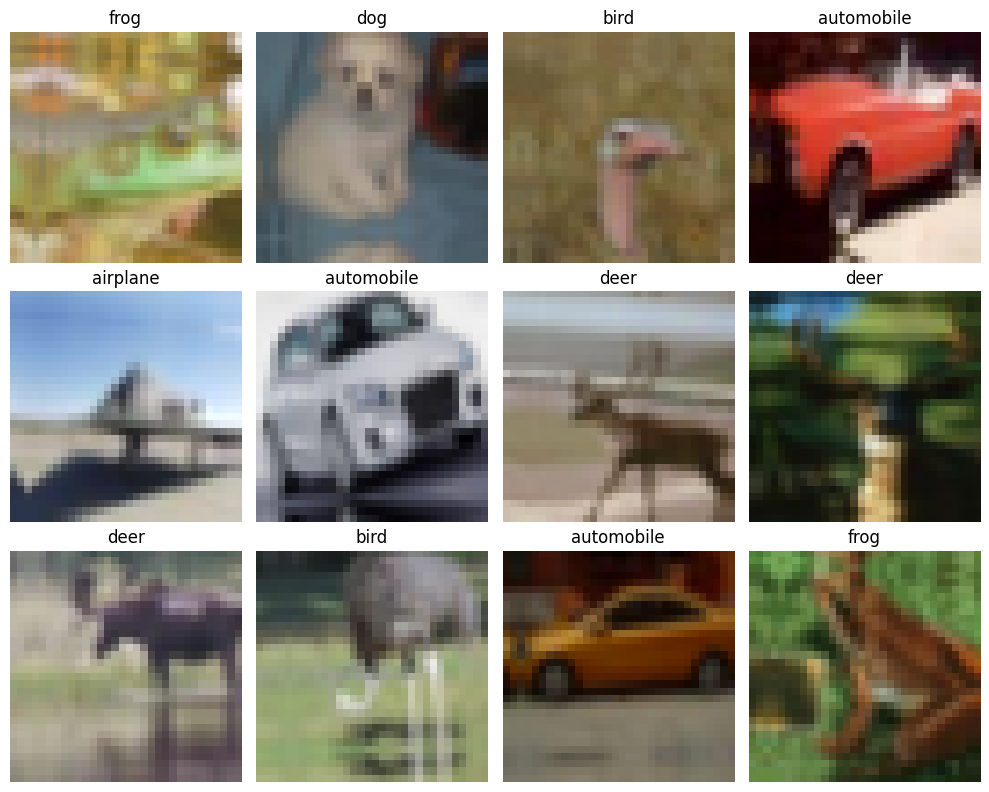

In [5]:
import matplotlib.pyplot as plt

# Lấy một ảnh augmented cho mỗi class, giữ nguyên cặp ảnh-nhãn từ train_ds.
preview_by_class = {}
for batch_images, batch_labels in train_ds:
    for image, label in zip(batch_images, batch_labels):
        class_id = int(label.numpy())
        if class_id not in preview_by_class:
            preview_by_class[class_id] = image
    if len(preview_by_class) == len(class_names):
        break

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for class_id, axis in enumerate(axes.flat):
    image = preview_by_class[class_id] * PIXEL_STD + PIXEL_MEAN
    image = tf.clip_by_value(image, 0.0, 1.0)
    axis.imshow(image.numpy())
    axis.set_title(class_names[class_id])
    axis.axis("off")

fig.suptitle("One augmented training image per CIFAR-10 class")
fig.tight_layout()
plt.show()

## CNN theo kiến trúc notebook mẫu

Bốn block có lần lượt 2 Conv2D với 32, 64, 128 và 256 filters; mỗi Conv2D dùng
ReLU, BatchNormalization và L2 weight decay 0.0001. Sau mỗi block là
MaxPooling2D và Dropout (0.2, 0.3, 0.4, 0.5). Cuối model dùng Flatten và Dense
softmax 10 class.

In [ ]:
WEIGHT_DECAY = 0.0001

model = tf.keras.Sequential(
    [
        tf.keras.Input(shape=(32, 32, 3)),

        # Block 1: 2 Conv2D layers, 32 filters.
        tf.keras.layers.Conv2D(
            32, (3, 3), padding="same", activation="relu",
            kernel_regularizer=tf.keras.regularizers.l2(WEIGHT_DECAY),
        ),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Conv2D(
            32, (3, 3), padding="same", activation="relu",
            kernel_regularizer=tf.keras.regularizers.l2(WEIGHT_DECAY),
        ),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),
        tf.keras.layers.Dropout(0.2),

        # Block 2: 2 Conv2D layers, 64 filters.
        tf.keras.layers.Conv2D(
            64, (3, 3), padding="same", activation="relu",
            kernel_regularizer=tf.keras.regularizers.l2(WEIGHT_DECAY),
        ),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Conv2D(
            64, (3, 3), padding="same", activation="relu",
            kernel_regularizer=tf.keras.regularizers.l2(WEIGHT_DECAY),
        ),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),
        tf.keras.layers.Dropout(0.3),

        # Block 3: 2 Conv2D layers, 128 filters.
        tf.keras.layers.Conv2D(
            128, (3, 3), padding="same", activation="relu",
            kernel_regularizer=tf.keras.regularizers.l2(WEIGHT_DECAY),
        ),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Conv2D(
            128, (3, 3), padding="same", activation="relu",
            kernel_regularizer=tf.keras.regularizers.l2(WEIGHT_DECAY),
        ),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),
        tf.keras.layers.Dropout(0.4),

        # Block 4: 2 Conv2D layers, 256 filters.
        tf.keras.layers.Conv2D(
            256, (3, 3), padding="same", activation="relu",
            kernel_regularizer=tf.keras.regularizers.l2(WEIGHT_DECAY),
        ),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Conv2D(
            256, (3, 3), padding="same", activation="relu",
            kernel_regularizer=tf.keras.regularizers.l2(WEIGHT_DECAY),
        ),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),
        tf.keras.layers.Dropout(0.5),

        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(len(class_names), activation="softmax"),
    ],
    name="cifar10_vgg_style_cnn",
)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

model.summary()

## Train và checkpoint theo validation loss

Adam bắt đầu ở learning rate 0.001. ReduceLROnPlateau giảm LR một nửa sau 3 epoch
không cải thiện val_loss, tối thiểu 0.00001. EarlyStopping patience=7 và khôi phục
weights tốt nhất. Giới hạn train là 80 epoch. Checkpoint và CSV history nằm trong
fruit-detection/checkpoints, kể cả khi mở notebook từ thư mục dataset/.
Checkpoint và history dùng tên riêng cho kiến trúc CNN kiểu notebook mẫu.
Tập test không tham gia chọn checkpoint.


In [ ]:
# DATA_DIR trỏ vào fruit-detection/cifar-10-batches-py.
PROJECT_DIR = DATA_DIR.parent
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_PATH = CHECKPOINT_DIR / "cifar10_vgg_style_cnn_best.keras"
HISTORY_PATH = CHECKPOINT_DIR / "cifar10_vgg_style_cnn_history.csv"

checkpoint_cb = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(CHECKPOINT_PATH),
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    verbose=1,
)
reduce_lr_cb = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    mode="min",
    factor=0.5,
    patience=3,
    min_delta=0.0,
    min_lr=1e-5,
    verbose=1,
)
early_stopping_cb = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    mode="min",
    patience=20,
    restore_best_weights=True,
    verbose=1,
)
history_logger_cb = tf.keras.callbacks.CSVLogger(str(HISTORY_PATH), append=False)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=200,
    callbacks=[checkpoint_cb, reduce_lr_cb, early_stopping_cb, history_logger_cb],
)

print(f"Best checkpoint: {CHECKPOINT_PATH}")
print(f"Training history: {HISTORY_PATH}")


## Đường cong huấn luyện

Train loss/accuracy được ghi trên ảnh có augmentation; validation dùng ảnh sạch.
Đồ thị learning rate giúp quan sát thời điểm scheduler giảm LR. CSV history ghi epoch từ 0;
đồ thị hiển thị epoch từ 1.

In [ ]:
epochs = range(1, len(history.history["loss"]) + 1)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for axis, metric, title in zip(axes[:2], ["loss", "accuracy"], ["Loss", "Accuracy"]):
    axis.plot(epochs, history.history[metric], label="Train (augmented)")
    axis.plot(epochs, history.history[f"val_{metric}"], label="Validation")
    axis.set(title=title, xlabel="Epoch", ylabel=title)
    axis.legend()
    axis.grid(alpha=0.3)

lr_values = history.history.get("learning_rate", history.history.get("lr"))
if lr_values is not None:
    axes[2].plot(epochs, lr_values)
    axes[2].set_yscale("log")
    axes[2].set(title="Learning rate", xlabel="Epoch", ylabel="LR")
    axes[2].grid(alpha=0.3)
else:
    axes[2].set_visible(False)

fig.tight_layout()
plt.show()

## Chẩn đoán bằng checkpoint tốt nhất

Đánh giá train không augment và validation với cùng chế độ inference.
Nếu cả hai accuracy thấp, xem xét khả năng học và tối ưu; nếu train cao hơn validation
rõ rệt, xem xét overfit. Chỉ dùng test_ds để đánh giá cuối sau khi chọn cấu hình bằng validation.

In [ ]:
best_model = tf.keras.models.load_model(str(CHECKPOINT_PATH))
train_clean_metrics = best_model.evaluate(train_clean_ds, return_dict=True, verbose=1)
val_metrics = best_model.evaluate(val_ds, return_dict=True, verbose=1)

print("Train không augment:", train_clean_metrics)
print("Validation:", val_metrics)
print(f"Accuracy gap (train - val): "
      f"{train_clean_metrics['accuracy'] - val_metrics['accuracy']:.4f}")